Cart Abandonment Analysis

In [4]:
import pandas as pd

df = pd.read_csv("../data/events.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Columns:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Missing values:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [6]:
# 1. Event types and their counts
print("Event Counts:")
display(df["event"].value_counts())

# 2. Unique visitors
print("Unique visitors:", df["visitorid"].nunique())

# 3. Unique products
print("Unique items:", df["itemid"].nunique())

# 4. Unique transactions
print("Unique transactions:", df["transactionid"].nunique())

# 5. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 6. Sample records
display(df.sample(10, random_state=42))

Event Counts:


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Unique visitors: 1407580
Unique items: 235061
Unique transactions: 17672
Duplicate rows: 460


,timestamp,visitorid,event,itemid,transactionid
486798,1435193216976,50734,view,4442,NaN
1145255,1440996903983,355903,view,269631,NaN
1601366,1431280237515,1066758,view,221329,NaN
843976,1439507864399,1049477,view,23683,NaN
2524686,1437601159324,143239,view,6552,NaN
1114057,1440868598798,762715,view,46130,NaN
2361757,1436909226237,976898,view,82224,NaN
1109279,1440779774908,269679,view,164327,NaN
1786895,1431989552823,599789,view,386382,NaN
2297273,1436682358636,270991,view,369195,NaN


In [7]:
df["event_datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

display(df[["timestamp", "event_datetime", "event"]].head())

print("Date range:")
print("Start:", df["event_datetime"].min())
print("End:", df["event_datetime"].max())

,timestamp,event_datetime,event
0,1433221332117,2015-06-02 05:02:12.117,view
1,1433224214164,2015-06-02 05:50:14.164,view
2,1433221999827,2015-06-02 05:13:19.827,view
3,1433221955914,2015-06-02 05:12:35.914,view
4,1433221337106,2015-06-02 05:02:17.106,view


Date range:
Start: 2015-05-03 03:00:04.384000
End: 2015-09-18 02:59:47.788000


In [8]:
# Count each event type
event_counts = df["event"].value_counts()

print("Event Distribution:")
display(event_counts.to_frame(name="count"))

# Calculate event percentages
event_percentages = (
    df["event"].value_counts(normalize=True) * 100
).round(2)

print("Event Percentages:")
display(event_percentages.to_frame(name="percentage"))

Event Distribution:


,count
event,
view,2664312
addtocart,69332
transaction,22457


Event Percentages:


,percentage
event,
view,96.67
addtocart,2.52
transaction,0.81


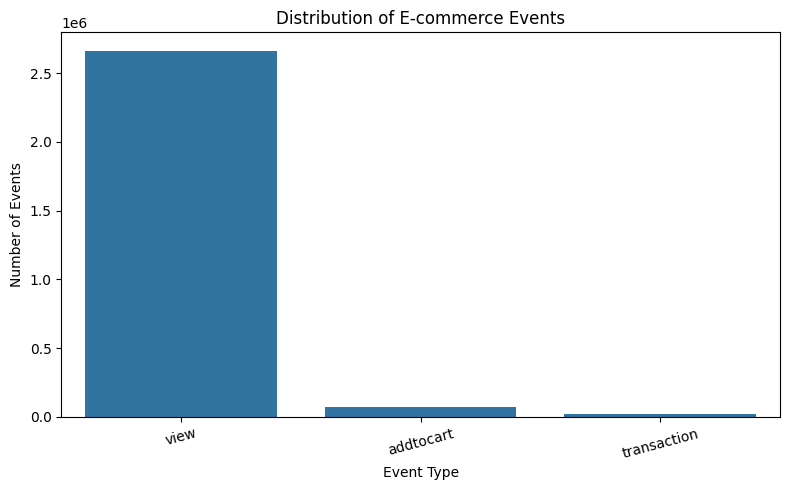

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="event",
    order=df["event"].value_counts().index
)

plt.title("Distribution of E-commerce Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
print("Total events:", len(df))
print("Unique visitors:", df["visitorid"].nunique())
print("Unique products:", df["itemid"].nunique())
print("Completed transactions:", df["transactionid"].nunique())

Total events: 2756101
Unique visitors: 1407580
Unique products: 235061
Completed transactions: 17672


In [11]:
import pandas as pd
import numpy as np

# Create a fresh working copy
clean_df = df.copy()

# Convert timestamp to datetime
clean_df["event_datetime"] = pd.to_datetime(
    clean_df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# Remove invalid timestamps
clean_df = clean_df.dropna(
    subset=["event_datetime"]
).copy()

# Sort events by visitor and time
clean_df = clean_df.sort_values(
    ["visitorid", "event_datetime"]
).reset_index(drop=True)

print("Cleaned rows:", len(clean_df))
print("Unique visitors:", clean_df["visitorid"].nunique())
print("Event counts:")
print(clean_df["event"].value_counts())

Cleaned rows: 2755641
Unique visitors: 1407580
Event counts:
event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64


In [12]:
# Time difference between consecutive events
clean_df["time_diff"] = (
    clean_df.groupby("visitorid")["event_datetime"]
    .diff()
)

# Start a new session if gap exceeds 30 minutes
clean_df["new_session"] = (
    clean_df["time_diff"].isna()
    | (clean_df["time_diff"] > pd.Timedelta(minutes=30))
)

# Create session number for each visitor
clean_df["session_number"] = (
    clean_df.groupby("visitorid")["new_session"]
    .cumsum()
)

# Create a unique session ID
clean_df["session_id"] = (
    clean_df["visitorid"].astype(str)
    + "_"
    + clean_df["session_number"].astype(str)
)

print("Total sessions:", clean_df["session_id"].nunique())

display(clean_df.head(10))

Total sessions: 1761675


,timestamp,visitorid,event,itemid,transactionid,event_datetime,time_diff,new_session,session_number,session_id
0,1442004589439,0,view,285930,NaN,2015-09-11 20:49:49.439,NaT,True,1,0_1
1,1442004759591,0,view,357564,NaN,2015-09-11 20:52:39.591,0 days 00:02:50.152000,False,1,0_1
2,1442004917175,0,view,67045,NaN,2015-09-11 20:55:17.175,0 days 00:02:37.584000,False,1,0_1
3,1439487966444,1,view,72028,NaN,2015-08-13 17:46:06.444,NaT,True,1,1_1
4,1438969904567,2,view,325215,NaN,2015-08-07 17:51:44.567,NaT,True,1,2_1
5,1438970013790,2,view,325215,NaN,2015-08-07 17:53:33.790,0 days 00:01:49.223000,False,1,2_1
6,1438970212664,2,view,259884,NaN,2015-08-07 17:56:52.664,0 days 00:03:18.874000,False,1,2_1
7,1438970468920,2,view,216305,NaN,2015-08-07 18:01:08.920,0 days 00:04:16.256000,False,1,2_1
8,1438970905669,2,view,342816,NaN,2015-08-07 18:08:25.669,0 days 00:07:16.749000,False,1,2_1
9,1438971444375,2,view,342816,NaN,2015-08-07 18:17:24.375,0 days 00:08:58.706000,False,1,2_1


In [14]:
# Fast session summary using numeric event flags

clean_df["view"] = (clean_df["event"] == "view").astype("int8")
clean_df["cart"] = (clean_df["event"] == "addtocart").astype("int8")
clean_df["purchase"] = (clean_df["event"] == "transaction").astype("int8")

session_summary = clean_df.groupby("session_id", sort=False).agg(
    visitorid=("visitorid", "first"),
    session_start=("event_datetime", "min"),
    session_end=("event_datetime", "max"),
    total_events=("event", "size"),
    viewed=("view", "max"),
    added_to_cart=("cart", "max"),
    purchased=("purchase", "max")
).reset_index()

print(session_summary.shape)
display(session_summary.head())

(1761675, 8)


,session_id,visitorid,session_start,session_end,total_events,viewed,added_to_cart,purchased
0,0_1,0,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175,3,1,0,0
1,1_1,1,2015-08-13 17:46:06.444,2015-08-13 17:46:06.444,1,1,0,0
2,2_1,2,2015-08-07 17:51:44.567,2015-08-07 18:20:57.845,8,1,0,0
3,3_1,3,2015-08-01 07:10:35.296,2015-08-01 07:10:35.296,1,1,0,0
4,4_1,4,2015-09-15 21:24:27.167,2015-09-15 21:24:27.167,1,1,0,0


In [15]:
# Sessions where at least one product was added to cart
cart_sessions = session_summary[
    session_summary["added_to_cart"] == 1
]

# Cart sessions with no purchase event
abandoned_sessions = cart_sessions[
    cart_sessions["purchased"] == 0
]

total_cart_sessions = len(cart_sessions)
total_abandoned = len(abandoned_sessions)
total_purchased = int(
    cart_sessions["purchased"].sum()
)

if total_cart_sessions > 0:
    abandonment_rate = (
        total_abandoned / total_cart_sessions
    ) * 100
else:
    abandonment_rate = 0

print("Total cart sessions:", total_cart_sessions)
print("Abandoned sessions:", total_abandoned)
print("Purchased sessions:", total_purchased)
print("Cart abandonment rate:", round(abandonment_rate, 2), "%")

Total cart sessions: 43924
Abandoned sessions: 31992
Purchased sessions: 11932
Cart abandonment rate: 72.83 %


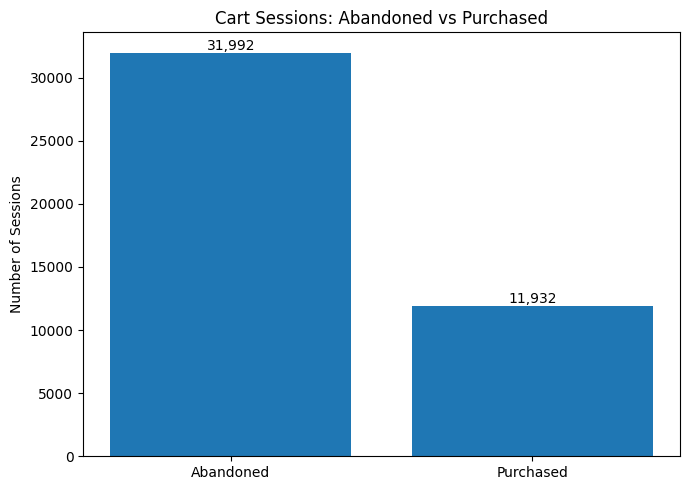

In [16]:
import matplotlib.pyplot as plt

labels = ["Abandoned", "Purchased"]
values = [total_abandoned, total_purchased]

plt.figure(figsize=(7, 5))
plt.bar(labels, values)

plt.title("Cart Sessions: Abandoned vs Purchased")
plt.ylabel("Number of Sessions")

for i, value in enumerate(values):
    plt.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [17]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Events",
        "Unique Visitors",
        "Total Sessions",
        "Cart Sessions",
        "Abandoned Sessions",
        "Purchased Cart Sessions",
        "Cart Abandonment Rate (%)"
    ],
    "Value": [
        len(clean_df),
        clean_df["visitorid"].nunique(),
        len(session_summary),
        total_cart_sessions,
        total_abandoned,
        total_purchased,
        round(abandonment_rate, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Events,2755641.00
1,Unique Visitors,1407580.00
2,Total Sessions,1761675.00
3,Cart Sessions,43924.00
4,Abandoned Sessions,31992.00
5,Purchased Cart Sessions,11932.00
6,Cart Abandonment Rate (%),72.83


In [18]:
import os

os.makedirs("../python/output", exist_ok=True)

session_summary.to_csv(
    "../python/output/session_summary.csv",
    index=False
)

kpi_summary.to_csv(
    "../python/output/kpi_summary.csv",
    index=False
)

print("CSV files saved successfully!")

CSV files saved successfully!
